# Analyzing results for Spatial Navigation

## Imports and configuration

In [1]:
import json
import matplotlib as mpl
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
import os
import pathlib
import pickle
from scipy.stats import ttest_rel
import sys
from tqdm import tqdm

import torch

from plots import plot_pos, scatter_pos, stemplot, violinplot, add_border_and_ticks
from helpers import optimal_decoder, gather_models, gather_test_data, momentum_plaus, \
                    dict_to_csv, wd_types_to_csvs
from metrics import wasserstein, calc_wds#, calc_kls

os.makedirs('pickle', exist_ok=True)
replay_dict_path = 'pickle/replay_unbiased_plaus.pkl'

## Load models and data

In [2]:
# Hyperparameters
unmask_every = 6 #3
epoch = 15000 
#epoch = 5000 #2500
t_quiescent = 500 #1000 #1000 #250 #100
quiescence = "same" 
lambda_scaling = False

In [3]:
results = pathlib.Path("../results")
noise = 0.0001
config_name = f"noisy_unbiased_unmask_every_{unmask_every}_{noise}"
seed_dirs = [results / "spatial_navigation" / f \
             for f in os.listdir(results / "spatial_navigation") if config_name in f]
seed_dirs

[PosixPath('../results/spatial_navigation/noisy_unbiased_unmask_every_6_0.0001_2'),
 PosixPath('../results/spatial_navigation/noisy_unbiased_unmask_every_6_0.0001_3'),
 PosixPath('../results/spatial_navigation/noisy_unbiased_unmask_every_6_0.0001_4'),
 PosixPath('../results/spatial_navigation/noisy_unbiased_unmask_every_6_0.0001_5'),
 PosixPath('../results/spatial_navigation/noisy_unbiased_unmask_every_6_0.0001_1'),
 PosixPath('../results/spatial_navigation/noisy_unbiased_unmask_every_6_0.0001_7'),
 PosixPath('../results/spatial_navigation/noisy_unbiased_unmask_every_6_0.0001_0'),
 PosixPath('../results/spatial_navigation/noisy_unbiased_unmask_every_6_0.0001_9'),
 PosixPath('../results/spatial_navigation/noisy_unbiased_unmask_every_6_0.0001_8'),
 PosixPath('../results/spatial_navigation/noisy_unbiased_unmask_every_6_0.0001_6')]

In [4]:
# Load models and their test data
models = gather_models(seed_dirs, epoch)
test_obs, test_pos, test_inits = gather_test_data(models)

## Simulating the model with various parameters

In [5]:
tau_a = 50
lambda_v_vals = [1, 0.7, 0.5, 0.3]
b_a_vals = [0, 0.005, 0.01]

In [6]:
# change iters from 11 to 51

In [7]:
replay = {}
quiescent_inputs = torch.zeros(models[0].task.batch_size, t_quiescent, 2)
for lambda_v in lambda_v_vals:
    for b_a in b_a_vals:
        key = str({'lambda_v': lambda_v, 'tau_a': tau_a, 'b_a': b_a})
        print(key)        
        replay[key] = []
        for (model, init) in zip(models, test_inits):
            # Using biologically plausible underdampening!
            pc_act = momentum_plaus(
                model, lambda_v=lambda_v, tau_a=tau_a, b_a=b_a, quiescence=quiescence,
                lambda_scaling=lambda_scaling, x=quiescent_inputs, init_state=init)[1]
            replay[key].append(optimal_decoder(
                model, pc_act, lr=(2e-1 if quiescence=='scaled' else 1e-1),
                verbose=True, iters=51))
        replay[key] = torch.stack(replay[key])
        print()

{'lambda_v': 1, 'tau_a': 50, 'b_a': 0}
0 5.73693296246347e-06
5 4.473120952752652e-06
10 4.157888270128751e-06
15 4.075813194504008e-06
20 4.033337972941808e-06
25 4.0042427826847415e-06
30 3.990238383266842e-06
35 3.985577677667607e-06
40 3.983097485615872e-06
45 3.98042402594001e-06
50 3.978237600676948e-06
0 6.4566393120912835e-06
5 4.338633516454138e-06
10 3.91868024962605e-06
15 3.7701797737099696e-06
20 3.697521151480032e-06
25 3.6387891668709926e-06
30 3.6186111174174584e-06
35 3.605370011428022e-06
40 3.595662747102324e-06
45 3.588783556551789e-06
50 3.5838734220305923e-06
0 5.425114522950025e-06
5 4.047263701068005e-06
10 3.660309857878019e-06
15 3.5688597108674003e-06
20 3.535705445756321e-06
25 3.5116588605887955e-06
30 3.4961342407768825e-06
35 3.4882912132161437e-06
40 3.4841650631278753e-06
45 3.4814436276064953e-06
50 3.4796155432559317e-06
0 5.137464540894143e-06
5 4.1123785194940865e-06
10 3.7224465359031456e-06
15 3.605171059462009e-06
20 3.570367198335589e-06
25 3.55

45 3.928008936782135e-06
50 3.926516910723876e-06
0 4.826730673812563e-06
5 4.006154085800517e-06
10 3.6669491692009615e-06
15 3.554698878360796e-06
20 3.5248774565843632e-06
25 3.515880052873399e-06
30 3.509904672682751e-06
35 3.504672122289776e-06
40 3.5006371490453603e-06
45 3.497901843729778e-06
50 3.4962440622621216e-06
{'lambda_v': 0.9, 'tau_a': 100, 'b_a': 0.2}
0 5.772818894911325e-06
5 4.906662979919929e-06
10 4.5732385842711665e-06
15 4.454263034858741e-06
20 4.408965196489589e-06
25 4.387200533528812e-06
30 4.374918717076071e-06
35 4.367909241409507e-06
40 4.363809694041265e-06
45 4.361179890111089e-06
50 4.359413651400246e-06
0 7.254287083924282e-06
5 4.688250555773266e-06
10 4.2908272916974965e-06
15 4.096871180081507e-06
20 4.0323243410966825e-06
25 3.97460644308012e-06
30 3.953758096031379e-06
35 3.946927336073713e-06
40 3.938446297979681e-06
45 3.9332048800133634e-06
50 3.929753802367486e-06
0 5.826356300531188e-06
5 4.41494194092229e-06
10 4.081878614670131e-06
15 3.977

40 3.9684837247477844e-06
45 3.964299594372278e-06
50 3.961992661061231e-06
0 6.045640930096852e-06
5 4.838994300371269e-06
10 4.426534360391088e-06
15 4.312029432185227e-06
20 4.2780106923601124e-06
25 4.256772172084311e-06
30 4.238751444063382e-06
35 4.22699258706416e-06
40 4.221321887598606e-06
45 4.218734375172062e-06
50 4.2170572669419926e-06
0 5.30307670487673e-06
5 4.493028882279759e-06
10 4.094423275091685e-06
15 3.928926162188873e-06
20 3.872006345773116e-06
25 3.854683654935798e-06
30 3.847649168164935e-06
35 3.842344540316844e-06
40 3.837800704786787e-06
45 3.834451035800157e-06
50 3.832356469501974e-06
{'lambda_v': 0.7, 'tau_a': 100, 'b_a': 0}
0 6.025233687978471e-06
5 4.749022536998382e-06
10 4.425091447046725e-06
15 4.339779025031021e-06
20 4.297474333725404e-06
25 4.268952125130454e-06
30 4.2550036596367136e-06
35 4.250407073413953e-06
40 4.24814334110124e-06
45 4.2456354094611015e-06
50 4.2434685383341275e-06
0 6.6158950176031794e-06
5 4.508707661443623e-06
10 4.1124594

In [8]:
# save repays
with open(replay_dict_path, 'wb') as file:
    pickle.dump(replay, file)

In [9]:
# load replays
with open(replay_dict_path, 'rb') as file:
    replay = pickle.load(file)

In [10]:
list(replay.values())[0].shape # seeds, N, T, 2

torch.Size([10, 200, 500, 2])

### Decoded outputs

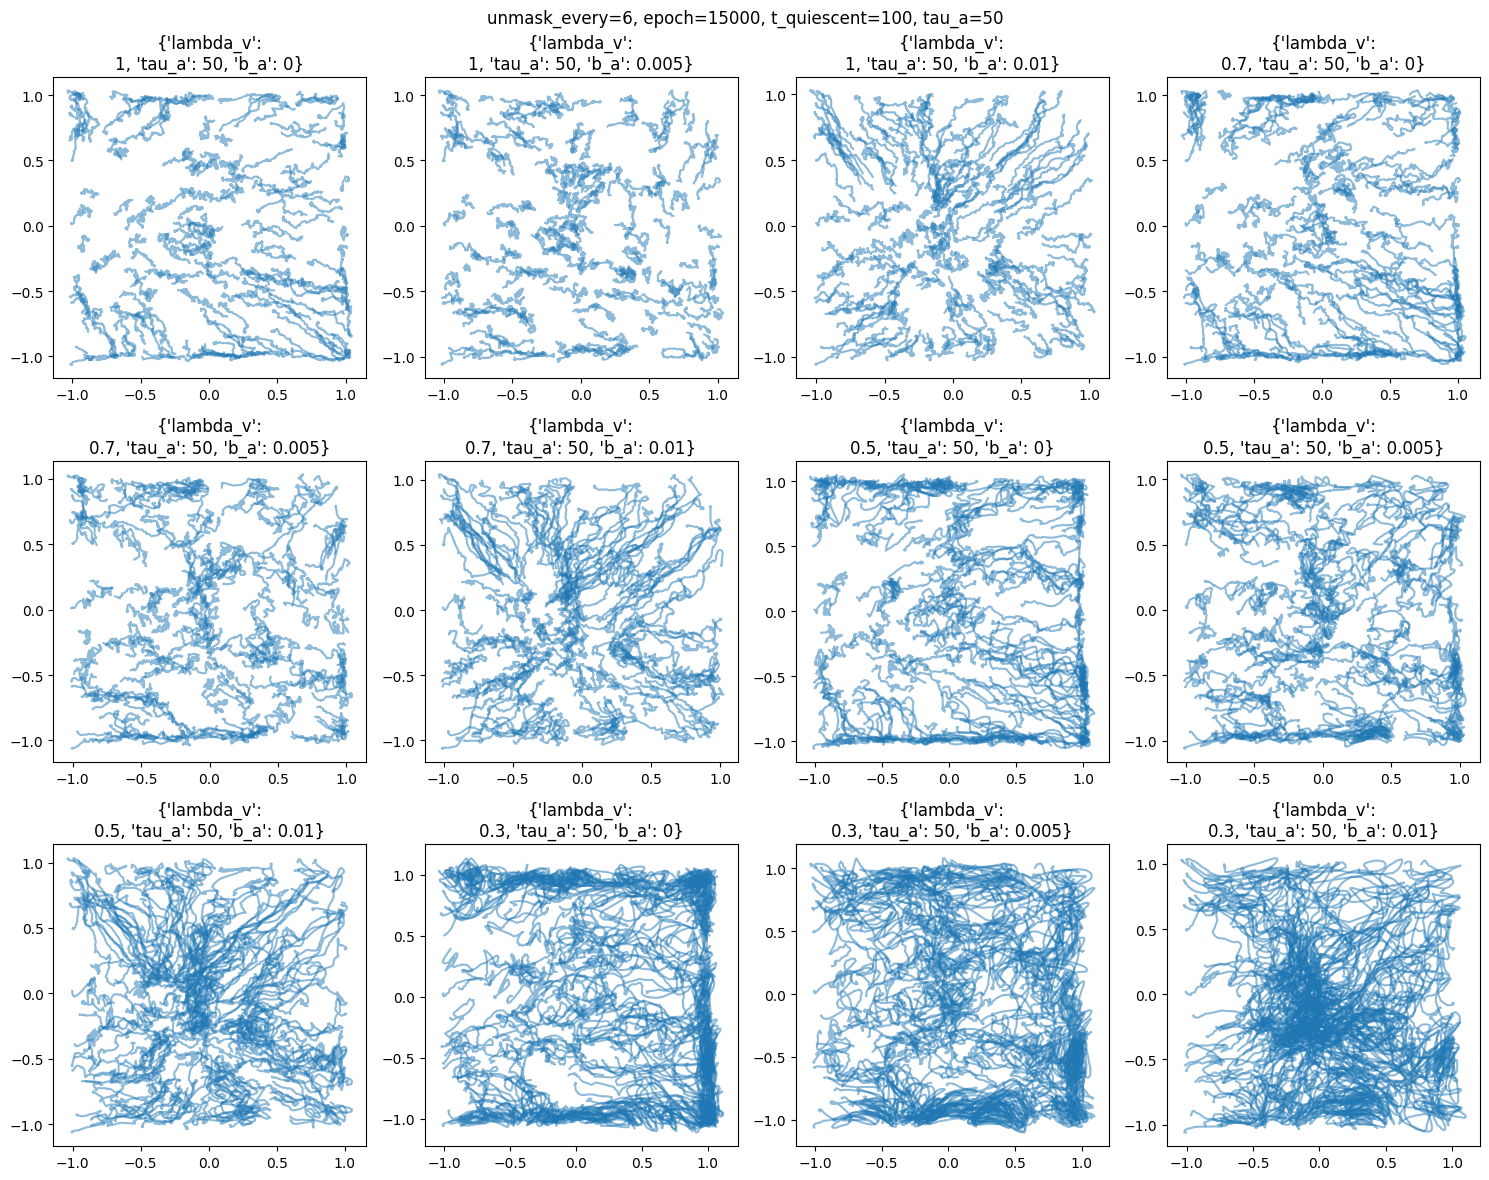

In [11]:
idx = 0
fig, axs = plt.subplots(nrows=3, ncols=4, figsize=(15,12))
axs = axs.flatten()
for i,(k,v) in enumerate(replay.items()):
    #plot_pos(axs[i], v, title = k[:k.index(' ')] + '\n' + k[k.index(' ')+1:])
    plot_pos(axs[i], v[idx,:,:100], title = k[:k.index(' ')] + '\n' + k[k.index(' ')+1:])
fig.suptitle(f'{unmask_every=}, {epoch=}, t_quiescent=100, {tau_a=}')
fig.tight_layout()

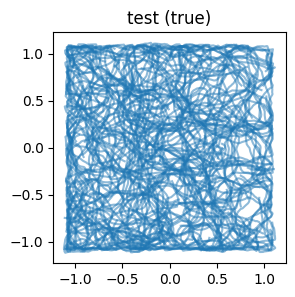

In [12]:
fig, ax = plt.subplots(1,1, figsize=(3,3))
plot_pos(ax, test_pos[idx], title='test (true)')

In [13]:
os.makedirs('../figures', exist_ok=True)

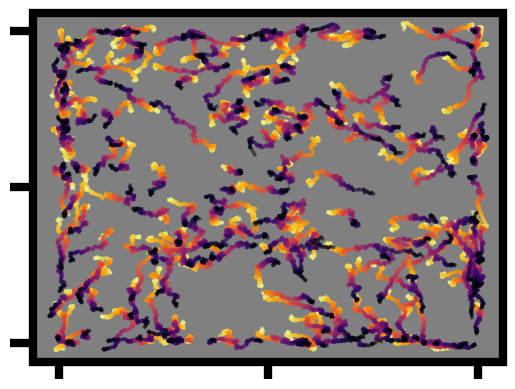

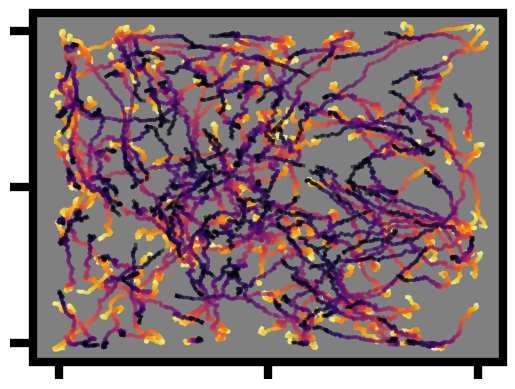

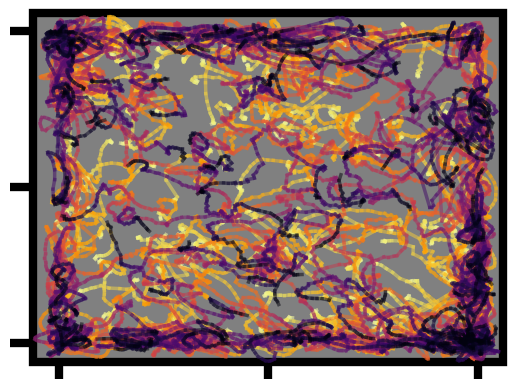

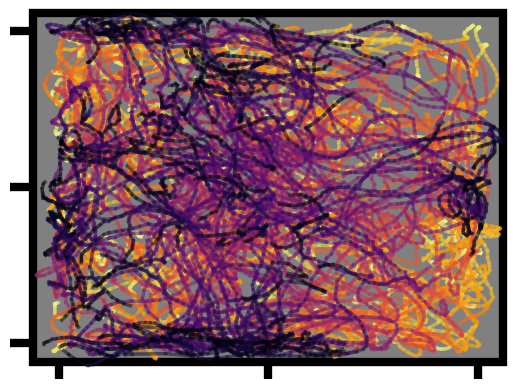

In [14]:
cmap = mpl.colormaps['inferno'] # 'plasma'
T_awake = test_pos.shape[2] # 100
xlim=(-1.12,1.12)
ylim=(-1.12,1.12)

for lv in (lambda_v_vals[0], lambda_v_vals[-1]):
    for ba in (b_a_vals[0], b_a_vals[-1]):
        fig, ax = plt.subplots(dpi=100)
        ax.axis('off')
        ax.set(xlim=xlim, ylim=ylim)
        add_border_and_ticks(ax, xlim, ylim, [-1,0,1], [-1,0,1],
                             extra_padding=(0.015,0.02)) # gray
        #x_hat = test_pos
        x_hat = replay[str({'lambda_v': lv, 'tau_a': tau_a, 'b_a': ba})]
        x_hat = x_hat.flatten(0,1) # combine the seed and sample dimensions
        for t in range(T_awake-1):
            # plot every 10th sample
            ax.plot(x_hat[::10, t:t+2,0].T, x_hat[::10, t:t+2,1].T,
                    c=cmap(1 - t/T_awake), alpha=0.5, linewidth=2.5)#, zorder=T-t)
        fig.savefig(f'../figures/plaus_unbiased_lambda_v={lv},b_a={ba}.png',
                    bbox_inches='tight', pad_inches=0)

### Wasserstein distance

In [15]:
os.makedirs('../csv', exist_ok=True)

In [16]:
wds = calc_wds(replay, test_pos)

100%|███████████████████████████████████████████| 12/12 [00:35<00:00,  2.96s/it]


In [17]:
dict_to_csv(wds, 'b_a', path='../csv/plaus_wds_unbiased.csv')

,lambda_v,tau_a,b_a=0.0,b_a=0.005,b_a=0.01
0,1.0,50,0.105714,0.113406,0.136581
1,0.7,50,0.109834,0.108139,0.140434
2,0.5,50,0.118090,0.105320,0.144014
3,0.3,50,0.150004,0.107770,0.168293


### velocity and distance

In [18]:
# velocity
    
# make sure that the number of timesteps are the same
# shape = seeds, N, T, 2
t_vel = test_pos.shape[2]
replay_vels = {k: v[:, :, :t_vel].diff(dim=2).square().sum(-1).sqrt() \
               for (k,v) in replay.items()}
test_vels = test_pos.diff(dim=2).square().sum(-1).sqrt()

replay_dists = {k: v.sum(-1) for k,v in replay_vels.items()}
test_dists = test_vels.sum(-1)

In [19]:
dist_avg = {k: v.mean().item() for k,v in replay_dists.items()}
dist_med = {k: v.median().item() for k,v in replay_dists.items()}

In [20]:
dist_med

{"{'lambda_v': 1, 'tau_a': 50, 'b_a': 0}": 0.6524094343185425,
 "{'lambda_v': 1, 'tau_a': 50, 'b_a': 0.005}": 0.7084224820137024,
 "{'lambda_v': 1, 'tau_a': 50, 'b_a': 0.01}": 0.8476393818855286,
 "{'lambda_v': 0.7, 'tau_a': 50, 'b_a': 0}": 0.7706695199012756,
 "{'lambda_v': 0.7, 'tau_a': 50, 'b_a': 0.005}": 0.8515899777412415,
 "{'lambda_v': 0.7, 'tau_a': 50, 'b_a': 0.01}": 1.0446404218673706,
 "{'lambda_v': 0.5, 'tau_a': 50, 'b_a': 0}": 0.9976916313171387,
 "{'lambda_v': 0.5, 'tau_a': 50, 'b_a': 0.005}": 1.1243565082550049,
 "{'lambda_v': 0.5, 'tau_a': 50, 'b_a': 0.01}": 1.3861401081085205,
 "{'lambda_v': 0.3, 'tau_a': 50, 'b_a': 0}": 1.6870064735412598,
 "{'lambda_v': 0.3, 'tau_a': 50, 'b_a': 0.005}": 1.9040350914001465,
 "{'lambda_v': 0.3, 'tau_a': 50, 'b_a': 0.01}": 2.2901086807250977}

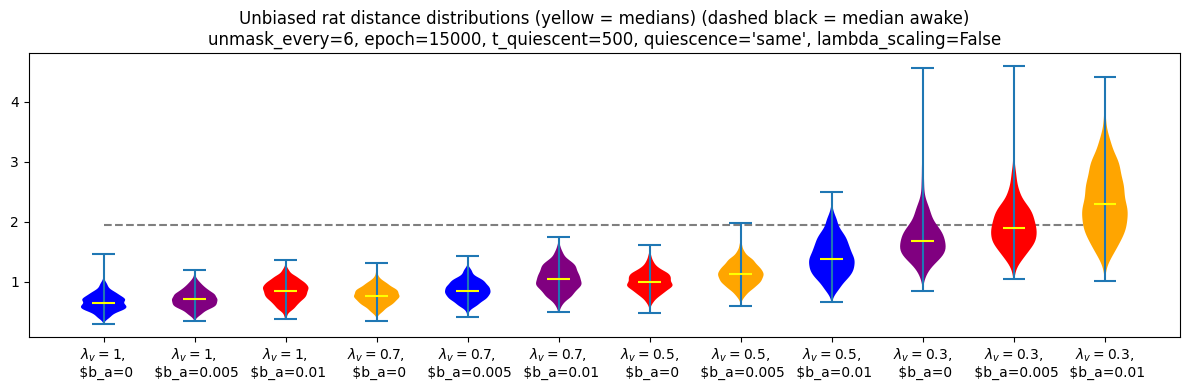

In [21]:
xlabels = [f"$\lambda_v={eval(k)['lambda_v']}$, \n $b_a={eval(k)['b_a']}" \
           for k in replay.keys()]

violinplot({k: v.sum(-1).flatten() for k,v in replay_vels.items()}, xlabels)
plt.title('Unbiased rat distance distributions (yellow = medians) (dashed black = median awake)' + \
          f'\n{unmask_every=}, {epoch=}, {t_quiescent=}, {quiescence=}, {lambda_scaling=}')
plt.hlines(test_vels.sum(-1).median(), 1, len(xlabels), linestyle='--', color='black', alpha=0.5, zorder=-1)
plt.tight_layout()
plt.show()

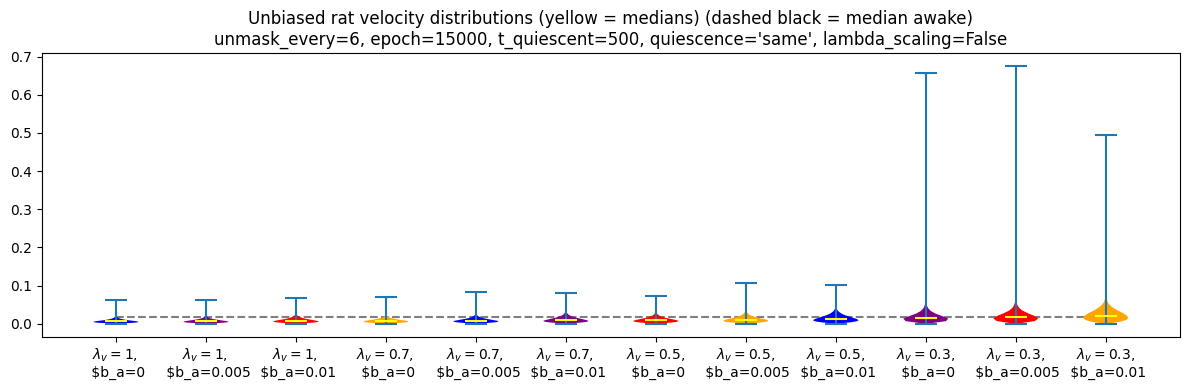

In [22]:
xlabels = [f"$\lambda_v={eval(k)['lambda_v']}$, \n $b_a={eval(k)['b_a']}" \
           for k in replay.keys()]

violinplot({k: v.flatten() for k,v in replay_vels.items()}, xlabels)
plt.title('Unbiased rat velocity distributions (yellow = medians) (dashed black = median awake)' + \
          f'\n{unmask_every=}, {epoch=}, {t_quiescent=}, {quiescence=}, {lambda_scaling=}')
plt.hlines(test_vels.median(), 1, len(xlabels), linestyle='--', color='black', alpha=0.5, zorder=-1)
plt.tight_layout()
plt.show()

### Exploration stuff

In [23]:
T_awake = test_pos.shape[-2]

def calculate_path_lens(x):
    assert x.ndim == 3 and x.shape[-1] == 2
    # differentiate along T (dim 1),
    # calculate dx (square sum sqrt),
    # sum along T (now dim -1)
    return x.diff(dim=1).square().sum(-1).sqrt().sum(-1)

def calculate_mean_displacements(x):
    assert x.ndim == 3 and x.shape[-1] == 2
    # subtract x wrt x(t=0) (time is dim 1),
    # calculate distance (square, sum, sqrt),
    # take mean along samples (dim 0)
    return (x - x[:,0:1]).square().sum(-1).sqrt().mean(0)

def calculate_variances(x):
    assert x.ndim == 3 and x.shape[-1] == 2
    # calculate variance of x along samples, take mean along dimensions.
    # the output should be a vector of length = # timestpes (dim 1)
    return x.var(0).mean(-1)

dist_avg, dist_std, dist_all, post_avg, post_std, md, variances = {}, {}, {}, {}, {}, {}, {}
for k, x_hat in replay.items():
    # combine seed and sample dim. x_hat shape = (-1, timesteps, 2)
    x_hat = x_hat.flatten(0,1)
    path_lens = calculate_path_lens(x_hat)
    post_lens = calculate_path_lens(x_hat[:,T_awake:]) # everything after T_awake

    # populate the dicts
    dist_avg[k] = path_lens.mean().item()
    dist_std[k] = path_lens.sum(-1).std().item()
    dist_all[k] = path_lens
    post_avg[k] = post_lens.mean().item()
    post_std[k] = post_lens.sum(-1).std().item()
    md[k] = calculate_mean_displacements(x_hat)
    variances[k] = calculate_variances(x_hat)

In [24]:
print("Distance p-values:")
p = {k: ttest_rel(list(dist_all.values())[0], v).pvalue
     for (k,v) in dist_all.items()}
p

Distance p-values:


{"{'lambda_v': 1, 'tau_a': 50, 'b_a': 0}": nan,
 "{'lambda_v': 1, 'tau_a': 50, 'b_a': 0.005}": 3.4512779313585995e-295,
 "{'lambda_v': 1, 'tau_a': 50, 'b_a': 0.01}": 0.0,
 "{'lambda_v': 0.7, 'tau_a': 50, 'b_a': 0}": 0.0,
 "{'lambda_v': 0.7, 'tau_a': 50, 'b_a': 0.005}": 0.0,
 "{'lambda_v': 0.7, 'tau_a': 50, 'b_a': 0.01}": 0.0,
 "{'lambda_v': 0.5, 'tau_a': 50, 'b_a': 0}": 0.0,
 "{'lambda_v': 0.5, 'tau_a': 50, 'b_a': 0.005}": 0.0,
 "{'lambda_v': 0.5, 'tau_a': 50, 'b_a': 0.01}": 0.0,
 "{'lambda_v': 0.3, 'tau_a': 50, 'b_a': 0}": 0.0,
 "{'lambda_v': 0.3, 'tau_a': 50, 'b_a': 0.005}": 0.0,
 "{'lambda_v': 0.3, 'tau_a': 50, 'b_a': 0.01}": 0.0}

In [25]:
print("Values above p=0.05:")
{k: v for (k,v) in p.items() if v > 0.05}

Values above p=0.05:


{}

In [26]:
os.makedirs('../csv/exploration', exist_ok=True)
print(calculate_path_lens(test_pos.flatten(0,1)).mean().item())
dict_to_csv(dist_avg, col_param='b_a', path='../csv/exploration/plaus_exploration_distance_unbiased.csv')

1.9467146396636963


,lambda_v,tau_a,b_a=0.0,b_a=0.005,b_a=0.01
0,1.0,50,2.943598,3.622195,3.936724
1,0.7,50,3.371677,4.132879,4.548412
2,0.5,50,4.328316,5.211905,5.799635
3,0.3,50,8.447452,9.661205,11.953718


### Additional figures

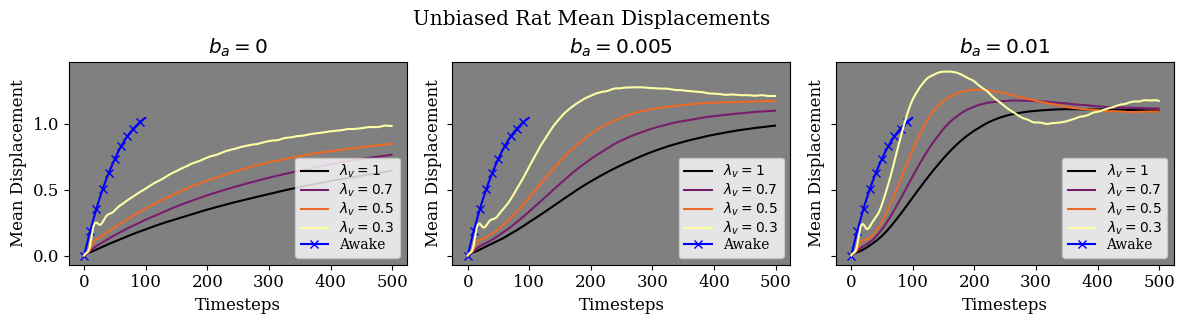

In [38]:
os.makedirs('../figures/mean_displacements', exist_ok=True)
os.makedirs('../figures/variance', exist_ok=True)

from cycler import cycler
cmap = plt.get_cmap('inferno')
plt.rc('axes', prop_cycle=cycler(color=cmap(np.linspace(0, 1, 4)))) # 4 lines

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 12 # previously 10

fig, axs = plt.subplots(nrows=1, ncols=len(b_a_vals), figsize=(12,3.5), sharex=True, sharey=True)
for k,v in md.items():
    k = eval(k)
    b, l = k["b_a"], k["lambda_v"]
    ax = axs[b_a_vals.index(b)]
    ax.plot(v, label=f'$\lambda_v = {k["lambda_v"]}$')
    ax.set(title=f'$b_a={b}$')
for ax in axs:
    ax.plot(calculate_mean_displacements(test_pos.flatten(0,1)),
            c='blue', marker='x', markevery=10, zorder=-1, label='Awake')
    ax.set(facecolor='gray', xlabel='Timesteps', ylabel='Mean Displacement'), 
    ax.legend(loc='lower right', fontsize=10, labelspacing=0.1)
fig.suptitle('Unbiased Rat Mean Displacements', y=0.92)
fig.tight_layout()
fig.savefig('../figures/mean_displacements/unbiased_md.pdf', bbox_inches='tight')

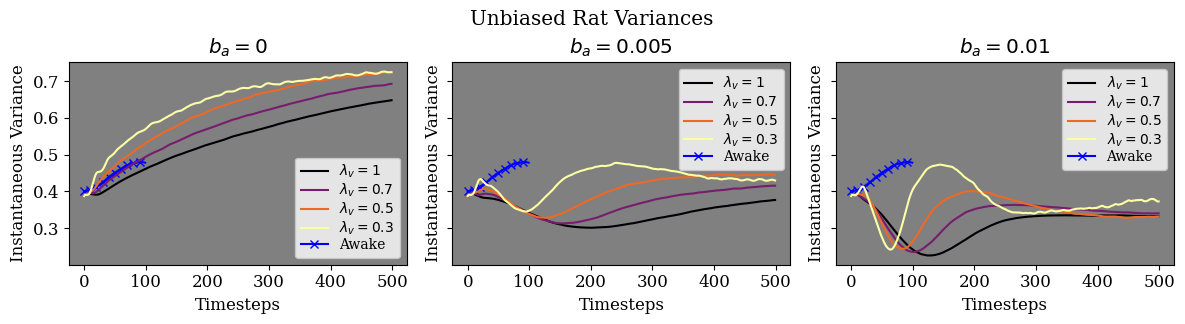

In [41]:
fig, axs = plt.subplots(nrows=1, ncols=len(b_a_vals), figsize=(12,3.5), sharex=True, sharey=True)
for k,v in variances.items():
    k = eval(k)
    b, l = k["b_a"], k["lambda_v"]
    ax = axs[b_a_vals.index(b)]
    ax.plot(v, label=f'$\lambda_v = {k["lambda_v"]}$')
    ax.set(title=f'$b_a={b}$')
for ax in axs:
    ax.plot(calculate_variances(test_pos.flatten(0,1)),
            c='blue', marker='x', markevery=10, zorder=-1, label='Awake')
    ax.set(facecolor='gray', xlabel='Timesteps', ylabel='Instantaneous Variance'), 
    ax.legend(fontsize=10, labelspacing=0.1)
fig.suptitle('Unbiased Rat Variances', y=0.92)
fig.tight_layout()
fig.savefig('../figures/variance/unbiased_var.pdf', bbox_inches='tight')